**Tarea Semana 8 – Segmentación de clientes con K-Means**

**Objetivo**

- Identificar cuántos **segmentos latentes de clientes** existen a partir de su comportamiento de compra y uso del sitio, **sin etiquetas previas**, usando K-Means.

**Variables de comportamiento**

| Variable | Descripción |
|---|---|
| `purchase_freq_month` | frecuencia de compras por mes |
| `avg_basket_usd` | ticket promedio por compra (USD) |
| `time_on_site_min` | tiempo de permanencia en el sitio (min) |
| `discount_sensitivity` | sensibilidad a descuentos (0 a 1) |
| `returns_rate` | tasa de devoluciones (0 a 0.8) |

**Importación de Librerías**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

pd.set_option('display.float_format', '{:.2f}'.format)
RANDOM_STATE = 42

**1. Carga y exploración de los datos**

In [4]:
df = pd.read_csv('dataset_segmentacion_clientes.csv')
print('Dimensiones:', df.shape)
print('Valores nulos:', df.isna().sum().sum())
df.head()

Dimensiones: (700, 7)
Valores nulos: 0


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.15,181.30,33.56,1.00,0.80,-1.81,-2.52
1,12.05,178.64,35.43,0.78,0.00,0.65,2.12
2,2.20,450.19,7.03,0.90,0.00,-0.05,-0.72
3,4.23,89.01,10.83,0.00,0.80,0.90,-2.97
4,1.72,449.77,7.25,0.00,0.00,0.39,2.42


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
purchase_freq_month,700.00,5.88,4.47,0.10,2.28,4.13,11.21,14.60
avg_basket_usd,700.00,248.17,154.90,86.99,90.77,180.22,449.72,452.97
time_on_site_min,700.00,16.78,12.91,3.16,6.60,9.97,34.34,38.35
discount_sensitivity,700.00,0.43,0.43,0.00,0.00,0.30,1.00,1.00
returns_rate,700.00,0.34,0.36,0.00,0.00,0.17,0.80,0.80
noise_gauss,700.00,0.02,1.01,-3.57,-0.65,0.08,0.73,2.86
noise_uniform,700.00,-0.01,1.68,-2.99,-1.42,0.01,1.41,3.00


**Observaciones:**

- 700 clientes, sin valores nulos.
- El dataset trae dos columnas extra, `noise_gauss` y `noise_uniform`. Por su nombre y su distribución (media ≈ 0, sin relación con el negocio) son **ruido aleatorio**: no describen comportamiento del cliente, así que **no se usan para el clustering** (en la sección 7 se verifica que incluirlas empeora la segmentación).
- Las escalas son muy distintas: `avg_basket_usd` va de ~87 a ~453, mientras que `discount_sensitivity` y `returns_rate` están entre 0 y 1. Esto confirma la pista de la consigna: **hay que escalar antes de aplicar K-Means**.

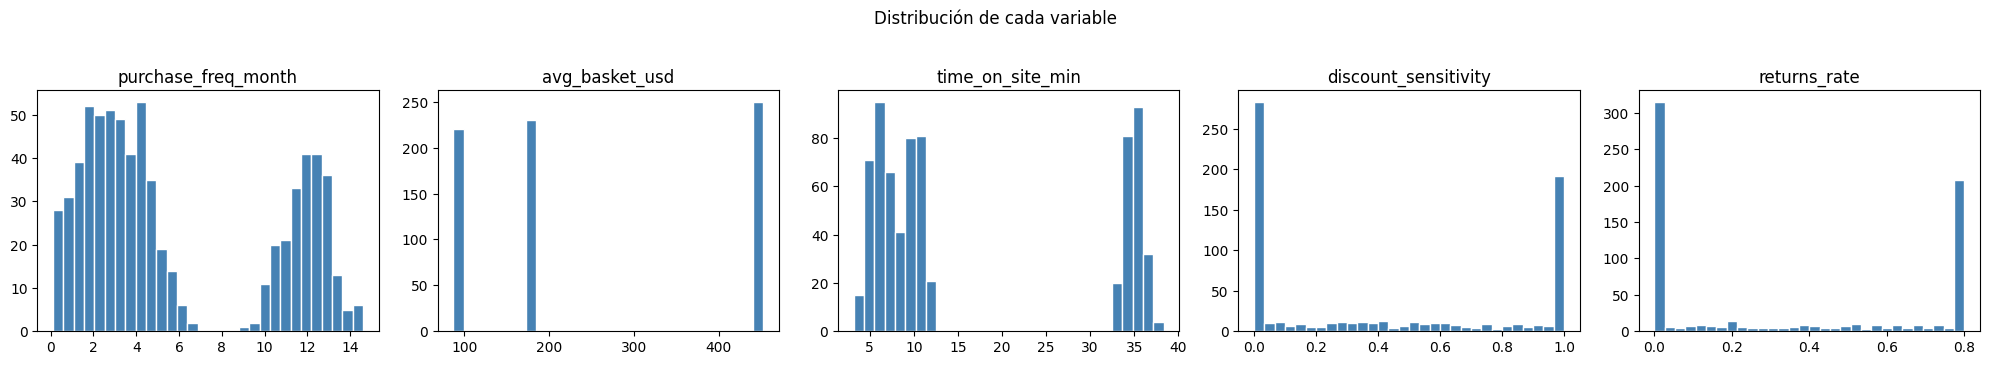

In [6]:
features = ['purchase_freq_month', 'avg_basket_usd', 'time_on_site_min',
            'discount_sensitivity', 'returns_rate']
X = df[features]

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, features):
    ax.hist(X[col], bins=30, color='steelblue', edgecolor='white')
    ax.set_title(col)
plt.suptitle('Distribución de cada variable', y=1.03)
plt.tight_layout()
plt.show()

Los histogramas ya anticipan estructura de grupos: `avg_basket_usd`, `purchase_freq_month` y `time_on_site_min` muestran **picos separados** (distribuciones multimodales), y `discount_sensitivity` y `returns_rate` se concentran en los extremos (0 o 1, y 0 o 0.8).

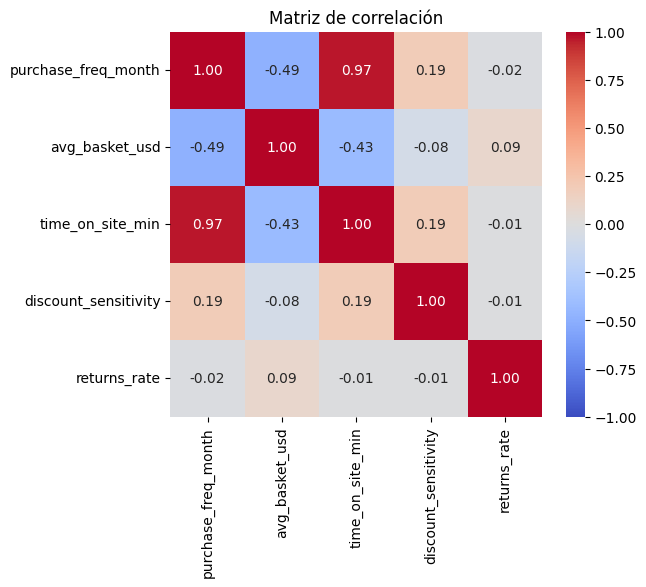

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

**2. Escalado de variables**

K-Means usa **distancia euclideana**: sin escalar, `avg_basket_usd` (rango de cientos) dominaría por completo la distancia y las variables entre 0 y 1 prácticamente no influirían. Se usa `StandardScaler` (media 0, desvío 1) para que todas pesen lo mismo.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

comparacion = pd.DataFrame({
    'desvío original': X.std(),
    'media escalada': X_scaled.mean(axis=0),
    'desvío escalado': X_scaled.std(axis=0),
})
comparacion

,desvío original,media escalada,desvío escalado
purchase_freq_month,4.47,-0.00,1.00
avg_basket_usd,154.90,-0.00,1.00
time_on_site_min,12.91,0.00,1.00
discount_sensitivity,0.43,0.00,1.00
returns_rate,0.36,-0.00,1.00


**3. Elección de k: método del codo (k = 2..6)**

Se entrena K-Means para cada k entre 2 y 6 y se registra la **inercia**. Como la inercia siempre baja al aumentar k, se busca el "codo": el punto a partir del cual agregar clusters deja de reducirla de forma importante. Como apoyo se calcula también el **coeficiente de silueta** (más alto = clusters más compactos y separados).

In [9]:
ks = range(2, 7)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300,
                random_state=RANDOM_STATE)
    km.fit(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, km.labels_))

resultados_k = pd.DataFrame({'k': list(ks), 'inercia': inercias, 'silueta': siluetas})
resultados_k['reducción inercia (%)'] = (-resultados_k['inercia'].pct_change() * 100)
resultados_k

,k,inercia,silueta,reducción inercia (%)
0,2,2088.88,0.40,NaN
1,3,1408.70,0.43,32.56
2,4,1173.44,0.43,16.70
3,5,997.74,0.42,14.97
4,6,762.47,0.46,23.58


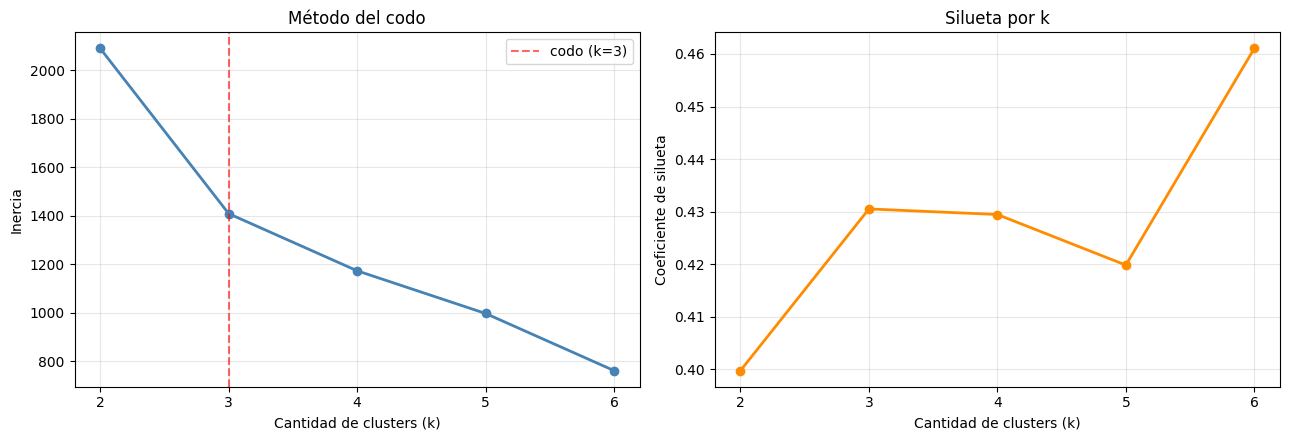

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(list(ks), inercias, 'o-', color='steelblue', linewidth=2)
ax1.axvline(3, color='red', linestyle='--', alpha=0.6, label='codo (k=3)')
ax1.set_xlabel('Cantidad de clusters (k)'); ax1.set_ylabel('Inercia')
ax1.set_xticks(list(ks)); ax2.set_xticks(list(ks))
ax1.set_title('Método del codo'); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(list(ks), siluetas, 'o-', color='darkorange', linewidth=2)
ax2.set_xlabel('Cantidad de clusters (k)'); ax2.set_ylabel('Coeficiente de silueta')
ax2.set_title('Silueta por k'); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación:**

- El salto más grande de la inercia está entre **k=2 y k=3** (cae ≈33%). A partir de k=3 la curva se aplana (bajadas de ≈17% y ≈15%): ahí está el **codo**, por lo que **k=3 es el valor más razonable** para describir los segmentos principales.
- La silueta mejora claramente de k=2 a k=3 y luego baja levemente en k=4 y k=5.
- Hay una segunda caída fuerte entre k=5 y k=6 y la silueta más alta está en **k=6**. Esto indica que, **dentro** de los 3 grandes segmentos, existen subgrupos diferenciados por sensibilidad a descuentos y tasa de devoluciones. Se analiza en la sección 6.

**Decisión:** se usa **k=3** como segmentación principal (justificada por el codo) y k=6 como segmentación fina complementaria.

**4. K-Means con k = 3**

In [11]:
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=10, max_iter=300,
                random_state=RANDOM_STATE)
df['cluster'] = kmeans.fit_predict(X_scaled)

print('Clientes por cluster:')
print(df['cluster'].value_counts().sort_index())

Clientes por cluster:
cluster
0    230
1    250
2    220
Name: count, dtype: int64


**Centroides**

Los centroides se calculan en el espacio escalado; con `inverse_transform` se llevan de vuelta a las **unidades originales** para poder interpretarlos.

In [12]:
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                          columns=features)
centroides.index.name = 'cluster'
centroides['n_clientes'] = df['cluster'].value_counts().sort_index()
centroides

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,n_clientes
cluster,,,,,,
0,11.96,180.00,35.02,0.54,0.33,230
1,1.85,450.12,5.97,0.36,0.38,250
2,4.09,89.96,10.00,0.38,0.30,220


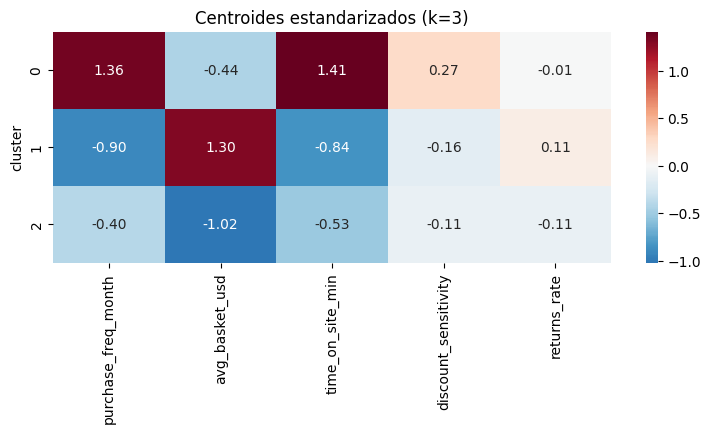

In [13]:
# Centroides en escala estandarizada: cuánto se aleja cada cluster del promedio (en desvíos)
centroides_z = pd.DataFrame(kmeans.cluster_centers_, columns=features)
plt.figure(figsize=(9, 3))
sns.heatmap(centroides_z, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Centroides estandarizados (k=3)')
plt.ylabel('cluster')
plt.show()

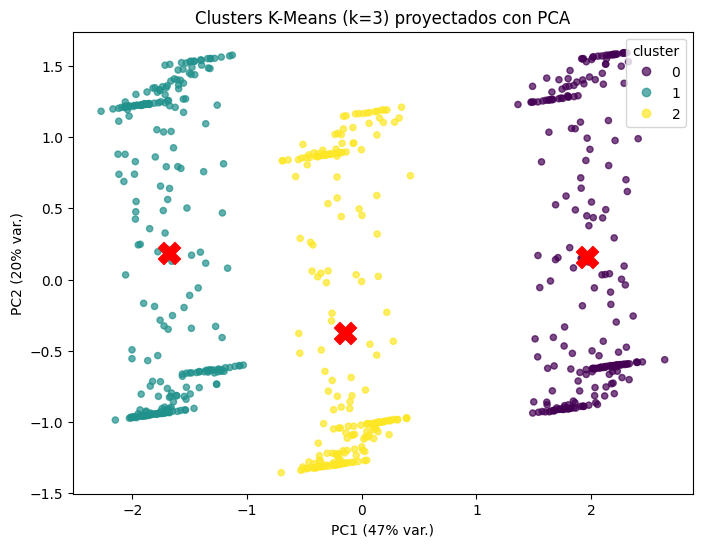

In [14]:
# Visualización en 2D con PCA (solo para graficar)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centros_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', s=20, alpha=0.7)
plt.scatter(centros_pca[:, 0], centros_pca[:, 1], c='red', marker='X', s=250, label='centroides')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} var.)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} var.)')
plt.title('Clusters K-Means (k=3) proyectados con PCA')
plt.legend(*sc.legend_elements(), title='cluster', loc='upper right')
plt.show()

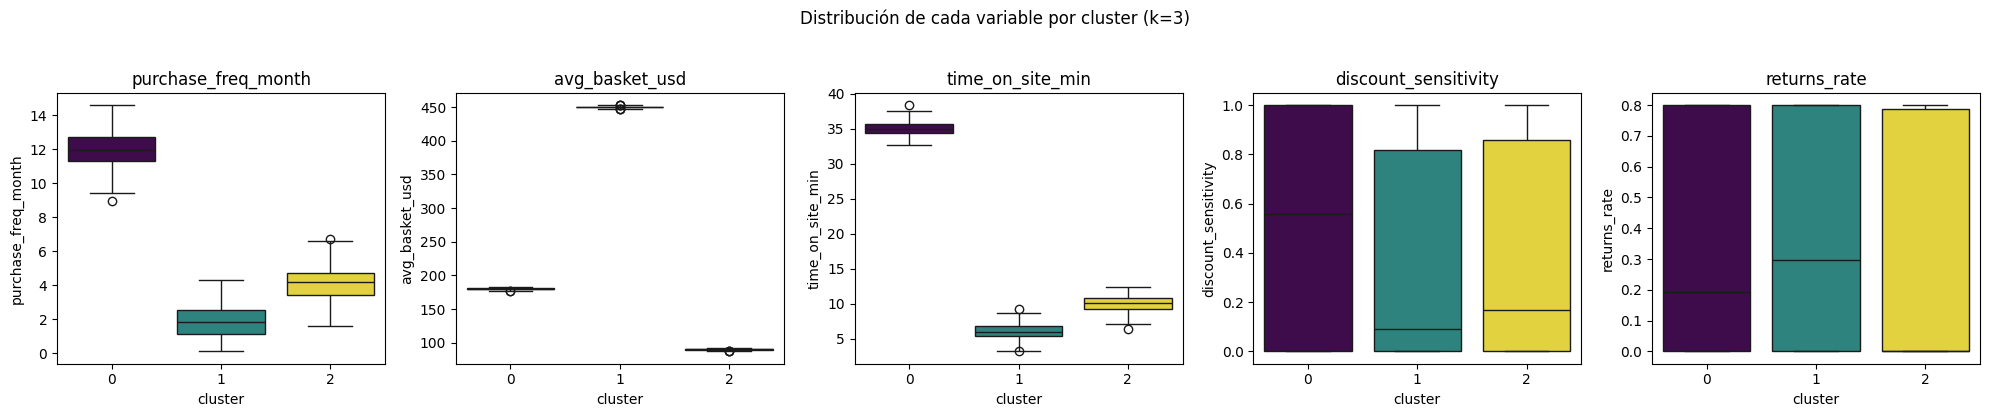

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, features):
    sns.boxplot(data=df, x='cluster', y=col, ax=ax, hue='cluster', palette='viridis', legend=False)
    ax.set_title(col)
plt.suptitle('Distribución de cada variable por cluster (k=3)', y=1.03)
plt.tight_layout()
plt.show()

**5. Perfiles de los clusters (k = 3)**

*(Los números de cluster pueden cambiar si se modifica `random_state`; los perfiles se mantienen.)*

| Cluster | Frecuencia | Ticket | Tiempo en sitio | Sensib. descuentos | Devoluciones | Perfil |
|---|---|---|---|---|---|---|
| **0** (230) | **alta** (~12/mes) | medio (~180 USD) | **alto** (~35 min) | media-alta (0.54) | media | **Compradores frecuentes / exploradores** |
| **1** (250) | **baja** (~1.9/mes) | **alto** (~450 USD) | bajo (~6 min) | baja (0.36) | media | **Premium esporádicos** |
| **2** (220) | media-baja (~4/mes) | **bajo** (~90 USD) | bajo (~10 min) | baja (0.38) | media | **Ocasionales de bajo valor** |

**Lectura de negocio:**

- **Cluster 0 – Frecuentes / exploradores:** compran mucho, pasan mucho tiempo en el sitio y son los más sensibles a descuentos. Es el patrón *"frecuencia alta + ticket bajo/medio + alta sensibilidad"* de la consigna. **Foco: promociones, cupones y programas de fidelización.**
- **Cluster 1 – Premium esporádicos:** compran poco pero con el ticket más alto y deciden rápido (poco tiempo en el sitio). Es el patrón *"compras esporádicas pero grandes, baja sensibilidad"*. **Foco: upselling premium, atención personalizada; no conviene regalar margen con descuentos.**
- **Cluster 2 – Ocasionales de bajo valor:** frecuencia y ticket bajos, poco tiempo en el sitio. **Foco: campañas de activación y aumento del ticket (combos, envío gratis desde un monto mínimo).**

Con k=3 la tasa de devoluciones queda **parecida en los tres grupos** (≈0.3–0.4): esa diferencia aparece recién al subdividir.

**6. Segmentación fina (k = 6)**

La consigna pide buscar grupos con **tiempo en sitio y tasa de devoluciones diferenciados**. Con k=3 eso no se ve, pero el codo secundario y la silueta máxima en k=6 sugieren subgrupos. Se analiza k=6.

In [16]:
kmeans6 = KMeans(n_clusters=6, init='k-means++', n_init=10, max_iter=300,
                 random_state=RANDOM_STATE)
df['cluster_6'] = kmeans6.fit_predict(X_scaled)

centroides6 = pd.DataFrame(scaler.inverse_transform(kmeans6.cluster_centers_), columns=features)
centroides6.index.name = 'cluster_6'
centroides6['n_clientes'] = df['cluster_6'].value_counts().sort_index()
centroides6.sort_values(['avg_basket_usd', 'returns_rate'])

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,n_clientes
cluster_6,,,,,,
5,4.23,89.88,10.05,0.35,0.73,84
0,4.01,90.01,9.97,0.40,0.03,136
1,11.95,179.99,35.13,0.11,0.35,110
4,11.97,180.00,34.92,0.93,0.31,120
3,1.81,450.05,6.08,0.35,0.73,122
2,1.88,450.19,5.87,0.36,0.04,128


In [17]:
# ¿Cómo se reparten los 6 subclusters dentro de los 3 clusters principales?
pd.crosstab(df['cluster'], df['cluster_6'], rownames=['cluster (k=3)'], colnames=['cluster (k=6)'])

cluster (k=6),0,1,2,3,4,5
cluster (k=3),,,,,,
0,0,110,0,0,120,0
1,0,0,128,122,0,0
2,136,0,0,0,0,84


**Interpretación:** cada uno de los 3 segmentos principales se divide en 2 subgrupos, siempre por una sola variable:

| Segmento principal | Se divide por | Subgrupos |
|---|---|---|
| Frecuentes / exploradores | **sensibilidad a descuentos** | "cazadores de ofertas" (≈0.93) vs. frecuentes **leales** que compran sin descuento (≈0.11) |
| Premium esporádicos | **tasa de devoluciones** | premium que **devuelven mucho** (≈0.73) vs. premium que **casi no devuelven** (≈0.04) |
| Ocasionales de bajo valor | **tasa de devoluciones** | ocasionales con devoluciones altas (≈0.73) vs. bajas (≈0.03) |

Acciones sugeridas para los subgrupos:

- **Cazadores de ofertas:** responden a promociones; usarlas con cuidado para no erosionar margen.
- **Frecuentes leales:** clientes de alto valor que no necesitan descuento; premiar con beneficios no monetarios (acceso anticipado, envíos).
- **Premium con muchas devoluciones:** revisar descripciones, talles/fotos de productos caros y políticas de devolución; cada devolución de ticket alto es costosa.
- **Premium sin devoluciones:** el segmento más rentable; prioridad en upselling y retención.

Respecto al patrón *"exploran mucho y devuelven más vs. exploran poco y devuelven menos"*: en este dataset **el tiempo en el sitio no está asociado a las devoluciones** (correlación ≈0). El tiempo en sitio diferencia a los frecuentes del resto, mientras que las devoluciones separan subgrupos *dentro* de los segmentos de menor frecuencia.

**7. Verificación: ¿qué pasa si se incluyen las columnas de ruido?**

Se repite la segmentación agregando `noise_gauss` y `noise_uniform` para justificar su exclusión.

In [18]:
X_ruido = StandardScaler().fit_transform(df[features + ['noise_gauss', 'noise_uniform']])
comparacion_ruido = []
for k in ks:
    sil_sin = silhouette_score(X_scaled, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled))
    sil_con = silhouette_score(X_ruido, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_ruido))
    comparacion_ruido.append((k, sil_sin, sil_con))
pd.DataFrame(comparacion_ruido, columns=['k', 'silueta sin ruido', 'silueta con ruido'])

,k,silueta sin ruido,silueta con ruido
0,2,0.40,0.29
1,3,0.43,0.28
2,4,0.43,0.25
3,5,0.42,0.23
4,6,0.46,0.24


Al incluir las variables de ruido la silueta cae en todos los k (de ≈0.43 a ≈0.28 en k=3): el ruido agrega distancia que no tiene que ver con el comportamiento del cliente y desdibuja los grupos. Excluirlas fue la decisión correcta.

**8. Conclusiones**

1. **Preprocesamiento:** se descartaron las dos columnas de ruido y se escalaron las 5 variables con `StandardScaler`, imprescindible porque K-Means se basa en distancias y las escalas eran muy distintas.
2. **Elección de k:** el método del codo para k = 2..6 muestra el quiebre en **k = 3**, que es la cantidad de segmentos principales. La silueta respalda esta elección y además sugiere una segmentación más fina con k = 6.
3. **Segmentos encontrados (k = 3):**
   - **Frecuentes / exploradores:** alta frecuencia, ticket medio, mucho tiempo en el sitio, más sensibles a descuentos → promociones y fidelización.
   - **Premium esporádicos:** baja frecuencia, ticket alto, baja sensibilidad → upselling premium.
   - **Ocasionales de bajo valor:** frecuencia y ticket bajos → activación y aumento del ticket.
4. **Segmentación fina (k = 6):** separa a los frecuentes según su sensibilidad a descuentos y a los demás según su tasa de devoluciones, lo que permite acciones más específicas (por ejemplo, atacar las devoluciones en los clientes premium).